# TRAYECTORIA-UCI
## Datos educativos y evidencia para la permanencia
**Proyecto 2 · Educación | ACA 1 · Computación en la Nube**  
**Especialización en Inteligencia Artificial · CUN**

La permanencia estudiantil puede estudiarse desde registros académicos y desde documentos que orientan el acompañamiento institucional. TRAYECTORIA-UCI articula ambas fuentes mediante una arquitectura de recuperación: resume perfiles del dataset entregado, indexa documentos oficiales colombianos sobre bienestar y acompañamiento y muestra evidencia pertinente junto con su contexto estadístico.

El notebook permite seguir cada transformación, comprobar los datos y repetir las consultas. La distribución de resultados educativos y los perfiles agregados constituyen el punto de partida; los documentos aportan conceptos y orientaciones para interpretar dimensiones de acompañamiento, sin trasladar resultados entre poblaciones.

## 1. Pregunta de trabajo y objetivo
**Pregunta.** ¿Cómo organizar un dataset de trayectorias educativas y un corpus de orientaciones sobre permanencia para recuperar pasajes pertinentes en lenguaje natural, conservar la procedencia de la evidencia y consultar perfiles estadísticos agregados?

**Objetivo.** Implementar una canalización reproducible de ingesta, fragmentación, embeddings e indexación vectorial que vincule temáticamente el dataset UCI 697 con documentos oficiales sobre permanencia y bienestar, y contraste la recuperación densa con un reordenamiento de candidatos, mediante preguntas de desarrollo y una reserva interna de pasajes fijados antes de evaluarlos.

El CSV contiene 4.424 registros y 36 variables predictoras, además de `Target`, con estados de graduación, abandono y matrícula en curso (Realinho et al., 2021). Este ejercicio describe los datos; no entrena un modelo predictivo ni asigna intervenciones individuales. Los perfiles se construyen a partir de beca, deuda y aprobación del primer semestre, mientras `Target` se reserva para resumir la composición observada de cada perfil. Su etiqueta no participa en la representación semántica de los documentos ni en el ordenamiento de las recuperaciones.

### Dos ámbitos de evidencia que deben mantenerse identificados
Los registros UCI proceden de Portugal; los documentos de bienestar y acompañamiento se refieren a educación superior en Colombia. La vinculación se realiza mediante temas compartidos, como financiación, acompañamiento académico y continuidad de los estudios. No existe correspondencia nominal entre estudiantes y documentos, y las diferencias entre perfiles no permiten atribuir causalidad ni estimar resultados para instituciones colombianas.

El sistema recupera pasajes y muestra estadísticas agregadas. Una respuesta que requiera aplicar una norma a una persona debe contrastar institución, fecha y competencia de la fuente; el alcance de ACA 1 corresponde a la capa de recuperación y su validación.

## 2. Diseño de la solución
| Etapa | Entrada y operación | Salida verificable |
|---|---|---|
| Integridad | CSV entregado y manifiesto de procedencia | Hash, dimensiones, valores ausentes y duplicados |
| Contexto estructurado | SQL y agrupaciones definidas sobre variables del dataset | Perfiles descriptivos con tamaño y composición |
| Corpus | Tres PDF oficiales y extracción por página | Texto, fuente y localización |
| Fragmentación | Párrafos con máximo de 280 tokens y solapamiento acotado | Pasajes trazables y sin truncamiento silencioso |
| Representación | Multilingual E5, prefijos de documento y consulta | Vectores normalizados de 384 dimensiones |
| Almacén | Qdrant, distancia coseno e inserción por lotes | Colección identificada por corpus y configuración |
| Consulta | Ámbito de fuente explícita → veinte candidatos por coseno → reordenamiento → Top-3 | Evidencia, dos puntuaciones diferenciadas y perfiles agregados |
| Evaluación | Doce preguntas de desarrollo + seis de reserva | Comparación de recuperación, pertinencia por pasaje y latencia |

La arquitectura implementada utiliza un clúster Qdrant Cloud Free; el mismo código admite una ejecución local explícita para inspeccionar el pipeline. El campo `remote_verified` solo puede ser verdadero cuando se comprueban el clúster remoto, sus puntos y una consulta real. La modalidad utilizada se conserva en la evidencia de cada ejecución.

## 3. Entorno autónomo y configuración
El notebook incluye el código y los manifiestos necesarios para ejecutarse por separado. Si la carpeta del proyecto no está presente, la primera celda la reconstruye; la ingesta restaura el CSV desde el archivo oficial UCI y verifica que sus bytes coincidan con el hash del CSV entregado. Los PDF se restauran desde los enlaces fijados en el manifiesto y también se verifican mediante SHA-256.

El paquete completo conserva las fuentes para reproducir la ejecución sin descargarlas nuevamente. En la modalidad autónoma se necesita acceso a los enlaces oficiales y al modelo de Hugging Face. Inicie el cuaderno en un kernel nuevo: la preparación contrasta las versiones instaladas con las dependencias fijadas, incluida la variante CPU de PyTorch.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, base64, zlib, subprocess
import importlib.metadata as package_metadata

# Código y manifiestos de TRAYECTORIA-UCI incluidos; no contiene credenciales.
EMBEDDED_PROJECT = "..."
locations = [Path.cwd(), Path.cwd()/"trayectoria_uci", Path("/content/trayectoria_uci")]
ROOT = next((p for p in locations if (p/"src/pipeline.py").is_file()), None)
if ROOT is None:
    ROOT = Path.cwd()/"trayectoria_uci"
    contents = json.loads(zlib.decompress(base64.b64decode(EMBEDDED_PROJECT)))
    for name, content in contents.items():
        path = ROOT/name
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(content, encoding="utf-8")
ROOT = ROOT.resolve()
pins = {}
for line in (ROOT/"requirements-lock.txt").read_text(encoding="utf-8").splitlines():
    line = line.strip()
    if line and not line.startswith("#") and "==" in line:
        package, version = line.split("==", 1)
        pins[package.strip()] = version.strip()
def mismatched_packages():
    different = []
    for package, expected in pins.items():
        try:
            actual = package_metadata.version(package)
        except package_metadata.PackageNotFoundError:
            actual = None
        actual = actual.split("+", 1)[0] if package == "torch" and actual else actual
        if actual != expected:
            different.append(package)
    return different
mismatches = mismatched_packages()
if "torch" in mismatches:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch=="+pins["torch"],
                           "--index-url", "https://download.pytorch.org/whl/cpu"])
if mismatches:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", str(ROOT/"requirements.txt")])
remaining = mismatched_packages()
if remaining:
    raise RuntimeError("Versiones sin verificar: "+", ".join(remaining))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Código, manifiestos y dependencias de TRAYECTORIA-UCI verificados.")

Código, manifiestos y dependencias de TRAYECTORIA-UCI verificados.


### Selección del backend y protección de credenciales
Para la ejecución cloud, cree un clúster Free en [Qdrant Cloud](https://cloud.qdrant.io/), genere su clave y configure `QDRANT_URL` y `QDRANT_API_KEY` en un archivo `.env` privado. Seleccione `RAG_BACKEND=cloud`; para la ejecución local, use `RAG_BACKEND=local`. El endpoint remoto debe utilizar HTTPS. Las claves se leen desde variables de entorno y nunca se imprimen.

Un fallo cloud detiene la operación e informa el tipo de error sin revelar credenciales. No se realiza una sustitución silenciosa por almacenamiento local. El modelo principal se selecciona con `EMBEDDING_PROVIDER=e5`; cualquier cambio de proveedor requiere generar representaciones e indexar una colección compatible antes de consultar. El modo `rerank` recupera veinte candidatos y reordena los pares pregunta-pasaje; `dense` conserva únicamente el orden por coseno. Ambos utilizan el mismo índice.

In [2]:
from pathlib import Path
import os, json, hashlib, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dotenv import load_dotenv
from src.pipeline import StudentEvidencePipeline

load_dotenv(ROOT / ".env", override=False)
BACKEND = os.getenv("RAG_BACKEND", "local").strip().lower()
PROVIDER = os.getenv("EMBEDDING_PROVIDER", "e5").strip().lower()
assert BACKEND in {"local", "cloud"}
assert PROVIDER in {"e5", "gemini2"}
RETRIEVAL = os.getenv("RETRIEVAL_METHOD", "rerank").strip().lower()
assert RETRIEVAL in {"dense", "rerank"}
pipeline = StudentEvidencePipeline(ROOT, backend=BACKEND, provider=PROVIDER,
                                   persistent=False, retrieval=RETRIEVAL)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)
print("Backend seleccionado:", BACKEND)
print("Proveedor de embeddings:", PROVIDER)
print("Método de recuperación:", RETRIEVAL)

Backend seleccionado: cloud
Proveedor de embeddings: e5
Método de recuperación: rerank


## 4. Dataset entregado: integridad y perfil general
El archivo `student_outcomes.csv` corresponde al conjunto *Predict Students’ Dropout and Academic Success*, distribuido por UCI bajo CC BY 4.0 (Realinho et al., 2021). El manifiesto identifica el archivo adjunto utilizado y conserva su hash; la verificación impide que una descarga posterior sustituya silenciosamente los datos por otra versión.

La ingesta normaliza las cabeceras, conserva los registros y registra valores ausentes y duplicados. Las consultas SQL permiten verificar la distribución de `Target` sin depender de cifras transcritas manualmente.

In [3]:
dataset = pipeline.ingest()
dataset_manifest = json.loads((ROOT / "data" / "dataset.json").read_text(encoding="utf-8"))
csv_path = ROOT / dataset_manifest["csv_path"]
actual_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
assert actual_sha256 == dataset_manifest["csv_sha256"]
records = pd.read_csv(csv_path, sep=dataset_manifest["delimiter"], encoding=dataset_manifest["encoding"])
records.columns = records.columns.str.strip()
assert len(records) == dataset["rows"]
display(pd.DataFrame([{
    "registros": dataset["rows"], "variables_predictoras": dataset["features"],
    "celdas_ausentes": dataset["missing_cells"], "duplicados_exactos": dataset["duplicate_rows"],
    "país": dataset["country"], "SHA-256_CSV": actual_sha256
}]))
with sqlite3.connect(ROOT / "results" / "cohorts.sqlite") as connection:
    outcomes = pd.read_sql_query(
        'SELECT Target AS estado, COUNT(*) AS n FROM student_records GROUP BY Target ORDER BY n DESC', connection)
outcomes["porcentaje"] = 100 * outcomes["n"] / outcomes["n"].sum()
display(outcomes.round(2))

,registros,variables_predictoras,celdas_ausentes,duplicados_exactos,país,SHA-256_CSV
0,4424,36,0,0,Portugal,3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


,estado,n,porcentaje
0,Graduate,2209,49.93
1,Dropout,1421,32.12
2,Enrolled,794,17.95


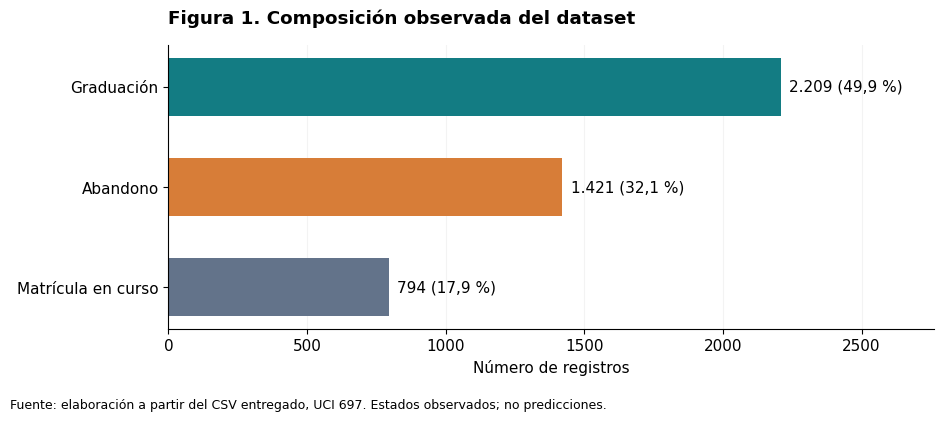

In [4]:
labels = {"Graduate": "Graduación", "Dropout": "Abandono", "Enrolled": "Matrícula en curso"}
colors = {"Graduate": "#137C83", "Dropout": "#D77D38", "Enrolled": "#63738A"}
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bars = ax.barh([labels[x] for x in outcomes["estado"]], outcomes["n"],
               color=[colors[x] for x in outcomes["estado"]], height=0.58)
ax.invert_yaxis()
ax.set_xlim(0, outcomes["n"].max() * 1.25)
ax.set_xlabel("Número de registros")
ax.set_title("Figura 1. Composición observada del dataset", loc="left", weight="bold", pad=15)
for bar, row in zip(bars, outcomes.itertuples()):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f"{row.n:,}".replace(",", ".") + " (" + f"{row.porcentaje:.1f}".replace(".", ",") + " %)", va="center")
ax.grid(axis="x", alpha=.15); ax.set_axisbelow(True)
fig.text(.01, .01, "Fuente: elaboración a partir del CSV entregado, UCI 697. Estados observados; no predicciones.", fontsize=9)
fig.tight_layout(rect=(0, .05, 1, 1))
plt.show()

## 5. Perfiles agregados y consulta SQL
Los perfiles se definen por variables que describen condiciones académicas y socioeconómicas: tenencia de beca, condición de deudor y unidades curriculares aprobadas en el primer semestre. Cada registro participa en una categoría de cada agrupación; por ello, las filas de distintos tipos de perfil no deben sumarse como si fueran grupos independientes.

`Target` se resume después de formar los perfiles. Los recuentos de abandono, graduación y matrícula en curso describen esa muestra, mientras la proporción de abandono se calcula como `dropout_count / n`. Las diferencias entre grupos no identifican el efecto de becas, deuda o aprobación, pues intervienen composición de la población, selección y otras condiciones no controladas.

In [5]:
with sqlite3.connect(ROOT / "results" / "cohorts.sqlite") as connection:
    cohorts = pd.read_sql_query("SELECT * FROM cohort_profiles ORDER BY grouping, group_value", connection)
assert cohorts["profile_id"].is_unique
assert (cohorts["n"] > 0).all()
assert np.allclose(cohorts["dropout_rate"], cohorts["dropout_count"] / cohorts["n"])
assert (cohorts[["dropout_count", "graduate_count", "enrolled_count"]].sum(axis=1) == cohorts["n"]).all()
display(cohorts)
print("Número de perfiles:", len(cohorts))
print("Tamaños por agrupación; cada agrupación debe cubrir el dataset:")
display(cohorts.groupby("grouping", as_index=False)["n"].sum())

Número de perfiles: 7
Tamaños por agrupación; cada agrupación debe cubrir el dataset:


,profile_id,thematic,grouping,group_value,n,dropout_count,graduate_count,enrolled_count,dropout_rate
0,approval_0,academic,aprobadas_sem1,0,718,570,77,71,0.793872
1,approval_1_5,academic,aprobadas_sem1,1-5,1712,647,559,506,0.377921
2,approval_6_plus,academic,aprobadas_sem1,6+,1994,204,1573,217,0.102307
3,scholarship_0,financial,beca,0,3325,1287,1374,664,0.387068
4,scholarship_1,financial,beca,1,1099,134,835,130,0.121929
5,debtor_0,financial,deudor,0,3921,1109,2108,704,0.282836
6,debtor_1,financial,deudor,1,503,312,101,90,0.620278


,grouping,n
0,aprobadas_sem1,4424
1,beca,4424
2,deudor,4424


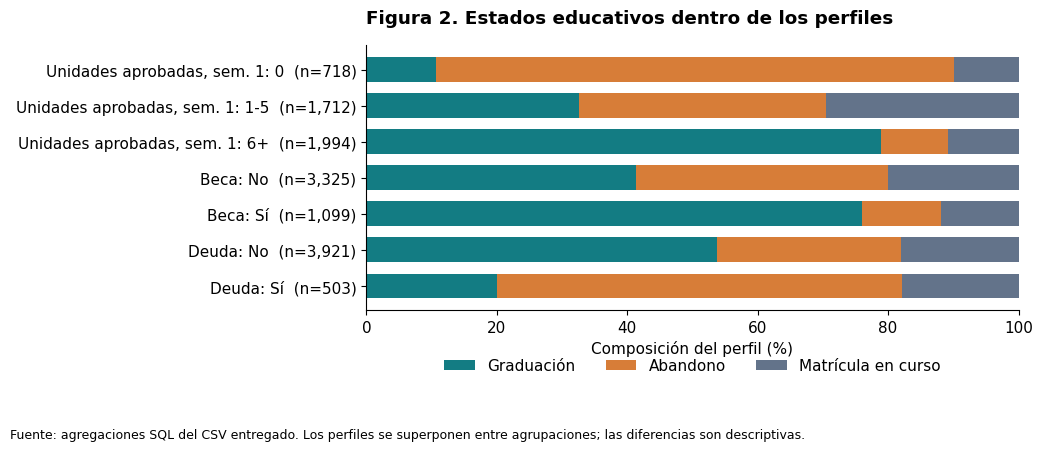

In [6]:
fig, ax = plt.subplots(figsize=(10.5, max(4.5, len(cohorts)*.5)))
left = np.zeros(len(cohorts))
group_names = {"aprobadas_sem1": "Unidades aprobadas, sem. 1", "beca": "Beca", "deudor": "Deuda"}
profile_labels = []
for row in cohorts.itertuples():
    value = {"0": "No", "1": "Sí"}.get(row.group_value, row.group_value) if row.grouping != "aprobadas_sem1" else row.group_value
    profile_labels.append(f"{group_names.get(row.grouping, row.grouping)}: {value}  (n={row.n:,})")
for column, label, color in [
    ("graduate_count", "Graduación", "#137C83"),
    ("dropout_count", "Abandono", "#D77D38"),
    ("enrolled_count", "Matrícula en curso", "#63738A")
]:
    share = 100 * cohorts[column].to_numpy() / cohorts["n"].to_numpy()
    ax.barh(profile_labels, share, left=left, color=color, label=label, height=.68)
    left += share
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Composición del perfil (%)")
ax.set_title("Figura 2. Estados educativos dentro de los perfiles", loc="left", weight="bold", pad=16)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.13), frameon=False)
fig.text(.01, .01, "Fuente: agregaciones SQL del CSV entregado. Los perfiles se superponen entre agrupaciones; las diferencias son descriptivas.", fontsize=9)
fig.tight_layout(rect=(0, .08, 1, 1))
plt.show()

### Del perfil estadístico al documento
Cada pasaje conserva una etiqueta temática y los identificadores de perfiles compatibles. Al consultar, el sistema recupera primero evidencia documental y utiliza los identificadores incluidos en el payload para consultar los perfiles SQL, con un filtro temático derivado de la pregunta; la vinculación hace visible qué dimensión del dataset acompaña la consulta.

El tamaño de un perfil y su composición se presentan como contexto del dataset portugués. Los documentos colombianos aportan orientaciones de alcance institucional o sectorial; esa relación conceptual no constituye validación de una intervención ni predicción de la trayectoria de un estudiante.

## 6. Corpus: tres documentos, tres ámbitos de acompañamiento
El corpus reúne **154 páginas físicas** en tres publicaciones oficiales. Los *Lineamientos de política de bienestar para instituciones de educación superior* ofrecen orientaciones de alcance nacional (Ministerio de Educación Nacional, 2016); la *Política para el éxito estudiantil y lineamientos* describe una experiencia institucional de acompañamiento (Universidad El Bosque, 2024); y la guía de la Universidad Nacional de Colombia se concentra en tutoría y apoyos para posgrado (Universidad Nacional de Colombia, Vicerrectoría Académica, Dirección Nacional de Programas de Posgrado, 2022).

| Documento | Extensión | Aporte al corpus |
|---|---:|---|
| MEN · Lineamientos de bienestar, 2016 | 55 páginas | Caracterización, promoción socioeconómica y gestión del bienestar |
| Universidad El Bosque · Política de éxito estudiantil, 2024 | 48 páginas | Tutorías, acompañamiento y seguimiento institucional |
| Universidad Nacional · Guía de acompañamiento de posgrado, 2022 | 51 páginas | Relación tutorial, bienestar y apoyos en posgrado |

La fuente MEN se conserva mediante una copia íntegra alojada por la Universidad de San Buenaventura Cali; el manifiesto registra tanto el origen ministerial como la descarga institucional y su hash. Los tres documentos mantienen sus propios destinatarios y versiones. Su recuperación aporta evidencia temática y no implica que sus disposiciones se apliquen automáticamente a la población portuguesa del dataset.

La extracción utiliza bloques de texto por página, normaliza espacios y detecta ciertos encabezados o pies repetidos. Se conservan los PDF originales para verificar tablas, composición visual y contexto de los pasajes; las páginas citadas siguen el orden físico de cada archivo.

### Fragmentos que conservan unidades de lectura
La fragmentación prioriza párrafos y establece un máximo de **280 tokens** por pasaje. Se acumulan párrafos completos y se conserva el último como solapamiento únicamente cuando tiene **50 tokens o menos** y cabe en la ventana siguiente. Los párrafos que exceden el límite se subdividen con un solapamiento de **40 tokens**; así se mantiene continuidad sin multiplicar innecesariamente el contenido. El corte respeta la página física, lo que permite volver al PDF y verificar la evidencia.

El tokenizador corresponde a la revisión fijada de E5. El máximo elegido deja margen bajo sus 512 tokens para los prefijos de recuperación, y cada entrada se comprueba antes de codificarla. Los metadatos incluyen documento, página, URL, posición en el texto, tema e identificadores de perfiles. El texto de `Target` y las estadísticas de resultados se mantienen fuera de los embeddings documentales.

In [7]:
chunks = pipeline.prepare_corpus()
display(pd.DataFrame(pipeline.corpus_summary))
display(pd.DataFrame([pipeline.chunk_stats]))
chunk_frame = pd.DataFrame(chunks)
assert chunk_frame["id"].is_unique
assert chunk_frame["text"].str.strip().ne("").all()
assert chunk_frame["token_count"].max() <= 280
display(chunk_frame.groupby("doc_id").agg(
    fragmentos=("id", "count"), páginas=("page", "nunique"),
    tokens_mediana=("token_count", "median"), tokens_máximo=("token_count", "max")
).reset_index())
example = chunks[len(chunks)//2]
display(pd.DataFrame([{k:example[k] for k in ["doc_id", "page", "thematic", "token_count", "char_start", "char_end", "profile_ids"]}]))
print(example["text"])

Secuencia didáctica virtual. Da lugar a la organización de los temarios del aula virtual por unidades o módulos que se establecen según el número de créditos de la asignatura que, a su vez, están definidos desde el Syllabus. Esta secuencia orienta al estudiante de un programa virtual con respecto a la estructura de la asignatura de tal manera que pueda identificar los módulos o unidades que la componen.

Trayectorias de aprendizaje. Recorrido de actividades académicas que una persona realiza para consolidar, fortalecer o transformar sus aprendizajes a lo largo de la vida, y que le permiten el desarrollo pleno de sus potencialidades, tener calidad de vida en lo personal, lo social y lo productivo (UEB, 2023)13.

Tutorías disciplinares. Espacios de formación que se brindan a los estudiantes fuera del horario de clases, guiados por los docentes y tutores pares para repasar, fortalecer conceptos, aclarar dudas y consolidar los aprendizajes de las diversas asignaturas del Plan de Estudios.


,doc_id,title,pages,sha256
0,men_bienestar_2016,Lineamientos de política de bienestar para instituciones de educación superior,55,9f42886b036a38606766368b62dcf238a1f136228db2cbd38457d95b2e6e4fa4
1,ueb_exito_2024,Política para el éxito estudiantil y lineamientos,48,5cf2ffa026693e563096c4f1dcd575cf4441414b45ae4d2b6474e1b1cc3483d8
2,unal_acompanamiento_2022,Guía de acompañamiento para estudiantes y tutores de Posgrado de la Universidad Nacional de Colo...,51,c4815810a3fd48df749b538f2888d4bcec3f107e770d4f99de4e628451f41464


,count,median_tokens,min_tokens,max_tokens,document_pages,pages_without_text,overlap_policy,max_chunk_tokens
0,319,212.0,23,280,154,8,ultimo_parrafo_completo_hasta_50_tokens; parrafo_largo_40_tokens,280


,doc_id,fragmentos,páginas,tokens_mediana,tokens_máximo
0,men_bienestar_2016,116,50,233.0,280
1,ueb_exito_2024,98,48,211.5,278
2,unal_acompanamiento_2022,105,48,207.0,280


,doc_id,page,thematic,token_count,char_start,char_end,profile_ids
0,ueb_exito_2024,19,academic,274,0,1292,"[approval_0, approval_1_5, approval_6_plus]"


## 7. Embeddings multilingües y coherencia del espacio vectorial
La configuración principal utiliza `intfloat/multilingual-e5-small`, un modelo abierto multilingüe de 384 dimensiones cuya revisión queda fijada en el proyecto (Intfloat, s. f.; Wang et al., 2024). Los documentos reciben el prefijo `passage:` y las consultas `query:`. La normalización L2 facilita el contraste entre el puntaje del motor vectorial y el coseno calculado de forma independiente.

La codificación se realiza por lotes y se conserva en una caché asociada con corpus, modelo y parámetros. Se verifica que exista exactamente un vector finito y de dimensión correcta por fragmento. La identidad de la colección impide mezclar representaciones de modelos diferentes.

El adaptador opcional para Gemini Embedding 2 conserva los roles conceptuales de consulta y documento mediante los prefijos `task: search result | query: …` y `title: … | text: …`. Google (s. f.) indica que Gemini 2 no admite `task_type`; una solicitud independiente por pasaje evita que varias entradas se agreguen en un solo vector. La selección `gemini2` exige su clave en una variable de entorno y genera una colección separada.

In [8]:
vectors = pipeline.encode()
assert vectors.shape[0] == len(chunks)
assert np.isfinite(vectors).all()
norms = np.linalg.norm(vectors, axis=1)
assert np.allclose(norms, 1, atol=1e-4)
display(pd.DataFrame([{"pasajes": vectors.shape[0], "dimensiones": vectors.shape[1],
    "norma_L2_mínima": norms.min(), "norma_L2_máxima": norms.max(),
    "memoria_float32_MiB": vectors.astype(np.float32).nbytes / 2**20}]))

,pasajes,dimensiones,norma_L2_mínima,norma_L2_máxima,memoria_float32_MiB
0,319,384,1.0,1.0,0.467285


## 8. Almacenamiento vectorial y presupuesto
Qdrant recibe los puntos mediante inserciones por lotes con confirmación de escritura; la colección utiliza distancia coseno y conserva el texto y sus metadatos como payload. La comprobación incluye conteo exacto, repetición de identificadores estables y consulta sobre el índice. La columna `remote_verified` diferencia la prueba remota de la ejecución local.

El plan Free documentado por Qdrant ofrece un nodo gestionado con 1 GB de RAM y 4 GB de disco (Qdrant, s. f.). La tabla de ejecución estima memoria de vectores y volumen del payload; el índice y la operación del servicio añaden consumo, de modo que esas cantidades deben contrastarse con el panel del clúster. E5 se ejecuta en el entorno de trabajo y evita cargos por una API de embeddings. El uso gratuito presupone conservar el plan y sus cuotas vigentes.

In [9]:
index_report = pipeline.index()
display(pd.DataFrame([index_report]))
assert index_report["stored_points"] == len(chunks)
assert index_report["expected_points"] == len(chunks)
assert index_report["idempotent_count"] == len(chunks)
assert index_report["dimension"] == vectors.shape[1]
assert "cosine" in str(index_report["metric"]).lower()
assert index_report["remote_verified"] is (BACKEND == "cloud")

,backend,remote_verified,collection,dimension,metric,expected_points,stored_points,idempotent_count,idempotency_test,batch_size,vector_mib,payload_mib,raw_data_mib,capacity_scope,self_match_score,verified_at
0,local,False,trajectory_e5_01986a6b2364ccd72a,384,cosine,319,319,319,repeticion_del_primer_lote_con_UUID_estables,64,0.467285,0.560608,1.027893,datos_brutos_sin_indices_ni_sobrecarga_del_servidor,1.0,2026-10-28T01:23:08.356738+00:00


## 9. Consulta: evidencia documental y contexto de perfiles
La recuperación convierte la pregunta en un vector con el mismo modelo de los documentos y solicita veinte candidatos por similitud coseno; el modo `rerank` los reordena antes de presentar los tres primeros pasajes. Para verificar la puntuación, se calcula $\operatorname{cos}(q,d)=\frac{q\cdot d}{\lVert q\rVert\lVert d\rVert}$ mediante NumPy y se compara con el valor de Qdrant.

El resultado presenta el texto y su fuente; los perfiles estadísticos aparecen como contexto complementario del tema. `score` conserva el coseno de Qdrant y `dense_rank` registra la posición en la búsqueda densa; `rerank_score` es la puntuación del Cross-Encoder y `rank` expresa el orden final. Los logits del reordenador y los cosenos tienen escalas diferentes: no deben mezclarse ni interpretarse como probabilidades de respuesta correcta.

Antes de consultar, una regla identifica si la pregunta nombra explícitamente una única institución del corpus —MEN, Universidad El Bosque o Universidad Nacional, con sus alias—; cuando hay una coincidencia inequívoca, aplica un filtro por documento. Si la pregunta no nombra una institución o menciona varias, se consulta el corpus completo. La regla utiliza únicamente el texto de la pregunta y los alias de las fuentes, sin leer las referencias esperadas. El campo `source_scope` registra su decisión.

El Cross-Encoder `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` evalúa conjuntamente la pregunta con el título y el texto de cada candidato, lo que permite atender correspondencias de contenido más específicas que una representación independiente (Cross-Encoder, s. f.; Sentence Transformers, s. f.). Se utiliza el modelo preentrenado, con revisión fijada, sin entrenarlo sobre estos documentos ni introducir las etiquetas del banco en el algoritmo. La comparación experimental debe mostrar si la pertinencia obtenida compensa su coste adicional de inferencia.

In [10]:
PREGUNTA = "¿Qué estrategias de apoyo financiero pueden favorecer la permanencia estudiantil?"
response = pipeline.search(PREGUNTA, k=3, include_cohorts=True)
hits = response["hits"]
hit_frame = pd.DataFrame(hits)
columns = ["rank", "dense_rank", "score", "rerank_score", "cosine_numpy", "cosine_error", "doc_id", "page", "thematic"]
display(hit_frame[[column for column in columns if column in hit_frame.columns]])
print("Ámbito de fuente:", response.get("source_scope", "corpus_completo"))
print("Candidatos considerados:", response["candidate_count"])
print("Tokens máximos por par pregunta-pasaje:", response["pair_max_tokens"])
if response["ranking_method"] == "rerank":
    display(pd.DataFrame(response["candidate_trace"]).sort_values("rerank_score", ascending=False).head(5))
assert len(hits) == 3
assert max(abs(h["cosine_error"]) for h in hits) < 1e-4
for hit in hits:
    ce_label = f" · logit CE {hit['rerank_score']:.4f}" if "rerank_score" in hit else ""
    display(Markdown(f"**{hit['rank']}. {hit['title']} · página {hit['page']} · coseno {hit['score']:.4f}{ce_label}**"))
    print(hit["text"])
    display(Markdown(f"[Ver pasaje en la fuente]({hit['url']}#page={hit['page']})"))
print("Tema de los perfiles:", response["cohort_theme"])
display(pd.DataFrame(response["cohorts"]))

Ámbito de fuente: {'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'policy': 'solo_una_fuente_explicita_activa_filtro; cero_o_varias_consultan_todo_el_corpus'}
Candidatos considerados: 20
Tokens máximos por par pregunta-pasaje: 316
Objetivos

Objetivo General

Promover un ambiente universitario que fomente el éxito estudiantil a través de la creación de un entorno inclusivo que reconozca y valore las diferencias individuales y colectivas; que garantice la igualdad de oportunidades y acceso a los recursos y apoyos necesarios para que los estudiantes permanezcan; logren los resultados de aprendizaje previstos en sus planes de estudio y rutas de formación escogidas autónomamente; se promueva su bienestar personal, emocional y psicosocial; se comprometan con su formación integral; y se gradúen oportunamente con las habilidades y competencias necesarias para insertarse en el mundo ocupacional.

Objetivos Específicos

• Dar un marco conceptual y o

Loading weights: 100%|##########| 201/201 [00:00<00:00, 3819.12it/s]


,rank,dense_rank,score,rerank_score,cosine_numpy,cosine_error,doc_id,page,thematic
0,1,15,0.846608,0.783968,0.846607,7.366518e-08,ueb_exito_2024,24,academic
1,2,14,0.846654,0.658015,0.846654,1.325504e-08,men_bienestar_2016,19,management
2,3,2,0.865847,-1.447393,0.865847,5.746140e-08,ueb_exito_2024,24,academic


,chunk_id,doc_id,page,dense_rank,score,cosine_error,rerank_score
14,bf556c7a-b342-5184-baa9-f2c7137f2cfb,ueb_exito_2024,24,15,0.846608,7.366518e-08,0.783968
13,73a73879-025e-5afb-a850-c8057dd4df53,men_bienestar_2016,19,14,0.846654,1.325504e-08,0.658015
1,c6ad0e0d-5f9c-5ec9-b2f0-371f96a08c71,ueb_exito_2024,24,2,0.865847,5.746140e-08,-1.447393
2,b79a33ae-dabf-52e1-a2da-0cf4256ca07d,ueb_exito_2024,30,3,0.860807,2.936488e-08,-1.876702
9,a4b5abf1-30a6-5de8-b5bb-fcbc4e8e85ed,men_bienestar_2016,28,10,0.848636,4.129950e-08,-1.915830


**1. Política para el éxito estudiantil y lineamientos · página 24 · coseno 0.8466 · logit CE 0.7840**

...

**2. Lineamientos de política de bienestar para instituciones de educación superior · página 19 · coseno 0.8467 · logit CE 0.6580**

[Ver pasaje en la fuente](https://usbcali.edu.co/wp-content/uploads/2023/10/lineamientos_de_politica_de_bienestar_para_ies.pdf#page=19)

**3. Política para el éxito estudiantil y lineamientos · página 24 · coseno 0.8658 · logit CE -1.4474**

[Ver pasaje en la fuente](https://www.unbosque.edu.co/sites/default/files/2024-10/PoliticadeExitoEstudiantil.pdf#page=24)

,profile_id,thematic,grouping,group_value,n,dropout_count,graduate_count,enrolled_count,dropout_rate
0,debtor_0,financial,deudor,0,3921,1109,2108,704,0.282836
1,debtor_1,financial,deudor,1,503,312,101,90,0.620278
2,scholarship_0,financial,beca,0,3325,1287,1374,664,0.387068
3,scholarship_1,financial,beca,1,1099,134,835,130,0.121929


### Explorar otras dimensiones
Las preguntas siguientes permiten contrastar recuperación académica y seguimiento de trayectorias. Pueden modificarse sin alterar el banco de evaluación, que se mantiene independiente de la exploración. Las tablas conservan fuente y página para facilitar la lectura del documento original.

In [11]:
exploration = [
    "¿Cómo puede organizarse el acompañamiento académico para estudiantes con dificultades de aprendizaje?",
    "¿Cómo se utilizan las alertas tempranas en el seguimiento de la permanencia?"
]
rows = []
for question in exploration:
    result = pipeline.search(question, k=3, include_cohorts=True)
    for hit in result["hits"]:
        rows.append({"pregunta": question, "rango_final": hit["rank"], "rango_denso": hit["dense_rank"], "coseno": hit["score"], "logit_CE": hit.get("rerank_score"),
                     "documento": hit["doc_id"], "página": hit["page"],
                     "tema_perfiles": result["cohort_theme"], "ámbito_fuente": str(result.get("source_scope", "corpus_completo")), "pasaje": hit["text"][:220]})
display(pd.DataFrame(rows))

,pregunta,rango_final,rango_denso,coseno,logit_CE,documento,página,tema_perfiles,ámbito_fuente,pasaje
0,¿Cómo puede organizarse el acompañamiento académico para estudiantes con dificultades de aprendi...,1,3,0.866604,0.624024,ueb_exito_2024,26,academic,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...","• Definir junto a los programas académicos y el Centro de Diversidad, Equidad e Inclusión (DEI) ..."
1,¿Cómo puede organizarse el acompañamiento académico para estudiantes con dificultades de aprendi...,2,13,0.852293,0.485268,ueb_exito_2024,25,academic,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...",Lineamientos para el éxito estudiantil\n\nCon el fin de alcanzar los objetivos de la presente Po...
2,¿Cómo puede organizarse el acompañamiento académico para estudiantes con dificultades de aprendi...,3,14,0.849666,-1.552464,ueb_exito_2024,35,academic,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...","Instancia Funciones\n\nCentro de Lenguas\n\n• Diseñar, definir e implementar la oferta de cursos..."
3,¿Cómo se utilizan las alertas tempranas en el seguimiento de la permanencia?,1,6,0.823604,-3.325261,ueb_exito_2024,14,management,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...","Adicionalmente, la presente Política se enlaza con los retos y objetivos del PDI 2022-2027, el c..."
4,¿Cómo se utilizan las alertas tempranas en el seguimiento de la permanencia?,2,3,0.833673,-4.278120,ueb_exito_2024,30,management,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...",de identificación de riesgos estudiantiles en pro de una respuesta articulada institucionalmente...
5,¿Cómo se utilizan las alertas tempranas en el seguimiento de la permanencia?,3,8,0.821328,-5.559035,ueb_exito_2024,31,management,"{'mode': 'all_sources', 'document_id': None, 'matched_source_ids': [], 'matched_aliases': {}, 'p...","• Garantizar que la información académica, como notas y fallas, esté actualizada dentro de los s..."


## 10. Comparación de recuperación y reserva interna
Se distinguen **doce preguntas de desarrollo** y **seis preguntas de reserva**. Las primeras permiten comparar recuperación densa y reordenamiento; las preguntas de reserva se redactaron a partir de las fuentes sin consultar los rankings y se utilizan con la configuración fijada. Ningún algoritmo de búsqueda recibe las respuestas esperadas o las expresiones de relevancia como entrada. La comparación actual mantiene el mismo filtro de institución explícita en ambos métodos; así, el contraste denso frente a rerank evalúa el reordenamiento bajo un ámbito de fuente común. La ejecución histórica original se conserva por separado, pues corresponde a una configuración anterior sin ese filtro.

La pertinencia exige localizar documento y página y satisfacer el ancla textual del pasaje. **Hit@3** indica si aparece evidencia pertinente entre los tres resultados; **MRR@3** pondera la posición del primer acierto; **nDCG@3** descuenta la ganancia según la posición y evita premiar repetidamente el mismo grupo de evidencia. El banco define una unidad de respuesta por pregunta y admite referencias alternativas dentro de ese grupo.

Cada pregunta se repite tres veces después del calentamiento: la comparación de desarrollo comprende 36 observaciones por método y la reserva, 18. La latencia incluye vectorización, consulta Qdrant, reordenamiento cuando corresponde, contraste del coseno y consulta SQL de perfiles; excluye la descarga y la carga inicial de modelos. Se trata de una medición del entorno, no de un acuerdo de nivel de servicio.

In [12]:
benchmark_path = ROOT / "data" / "evaluation.json"
benchmark = json.loads(benchmark_path.read_text(encoding="utf-8"))
benchmark_hash = hashlib.sha256(benchmark_path.read_bytes()).hexdigest()
print("SHA-256 del banco de desarrollo:", benchmark_hash)
def reference_table(bank):
    rows = []
    for item in bank["questions"]:
        expected = " | ".join(g["document_id"] + ": p. " + ", ".join(map(str, g["pages"])) + " · " + g.get("evidence_text", g.get("evidence_regex", "")) for g in item["gold"])
        rows.append({"id": item["id"], "pregunta": item["query"], "evidencia_esperada": expected})
    return pd.DataFrame(rows)
display(reference_table(benchmark))

# Ambos métodos comparten corpus, embeddings, filtro de fuente explícita y banco de desarrollo.
# Se conserva la primera ejecución histórica en results/baseline/.
pipeline.retrieval = "dense"
dense_metrics = dict(pipeline.evaluate(prefix="dense_comparison"))
pipeline.retrieval = "rerank"
metrics = dict(pipeline.evaluate())
comparison_keys = ["ranking_method", "n_queries", "hit_at_3", "mrr_at_3", "ndcg_at_3",
                   "latency_p50_ms", "latency_p95_ms", "candidate_pool"]
comparison = pd.DataFrame([dense_metrics, metrics])[comparison_keys]
display(comparison)
print("Diferencia de Hit@3, rerank menos dense:", round(metrics["hit_at_3"] - dense_metrics["hit_at_3"], 4))
print("Razón de latencias p50, rerank/dense:", round(metrics["latency_p50_ms"] / dense_metrics["latency_p50_ms"], 2))
evaluation = pd.DataFrame(pipeline.evaluation_records)
display(evaluation)
failures = evaluation.loc[evaluation["hit_at_3"].eq(0)]
print("Consultas de desarrollo sin evidencia pertinente en Top-3:", len(failures))
display(failures)

SHA-256 del banco de desarrollo: 92cc358cabdd5140985407948a4e2d81c84f03018e81a9c366623f578b8c6bca
Diferencia de Hit@3, rerank menos dense: 0.1667
Razón de latencias p50, rerank/dense: 63.29
Consultas de desarrollo sin evidencia pertinente en Top-3: 3


,id,pregunta,evidencia_esperada
0,T01,"Según los lineamientos del MEN, ¿qué apoyos contempla la promoción socioeconómica para personas ...","men_bienestar_2016: p. 28 · otorgamiento de becas, subsidios"
1,T02,"¿Cómo debería actualizarse la caracterización de la comunidad educativa, según el MEN?","men_bienestar_2016: p. 32 · ejercicio dinámico, sistemático"
2,T03,¿Qué características propone el MEN para un sistema institucional de bienestar?,men_bienestar_2016: p. 28 · Coherente. Flexible. Sostenible.
3,T04,"¿Para qué deben funcionar en doble vía los canales de comunicación de bienestar, de acuerdo con ...","men_bienestar_2016: p. 31 · recoger iniciativas, propuestas y opiniones"
4,T05,"En la Universidad El Bosque, ¿para qué sirven las tutorías disciplinares y quiénes las orientan?",ueb_exito_2024: p. 19 · fuera del horario de clases
5,T06,¿Qué estrategias prevé El Bosque para asignaturas que concentran pérdidas académicas?,"ueb_exito_2024: p. 26 · tutores pares, tutorías disciplinares"
6,T07,¿Con qué frecuencia mínima deben analizar las áreas de El Bosque la información del Observatorio...,ueb_exito_2024: p. 31 · 2 ejercicios anuales
7,T08,¿Qué dimensiones del compromiso estudiantil identifica la política de El Bosque?,ueb_exito_2024: p. 30 · motivación; sentido de pertenencia; persistencia
8,T09,"Según la guía de posgrado de la UNAL, ¿hacia qué servicios puede orientar el tutor cuando identi...",unal_acompanamiento_2022: p. 28 · instancias de bienestar universitario
9,T10,¿En qué decisiones del programa de posgrado deben asistir el tutor o el comité de tutores a los ...,unal_acompanamiento_2022: p. 29 · selección de asignaturas


,ranking_method,n_queries,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,candidate_pool
0,dense,12,0.583333,0.486111,0.510911,24.001042,30.220707,3
1,rerank,12,0.750000,0.652778,0.677577,1519.110551,1804.999845,20


,id,query,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,top1_score,stable_top3,ranking_method,source_scope_mode,source_scope_document,relevant_ranks,top1_rerank_score
0,T01,"Según los lineamientos del MEN, ¿qué apoyos contempla la promoción socioeconómica para personas ...",1,1.000000,1.00000,1431.996697,1550.371074,0.849854,True,rerank,explicit_single_source,men_bienestar_2016,1,1.586158
1,T02,"¿Cómo debería actualizarse la caracterización de la comunidad educativa, según el MEN?",0,0.000000,0.00000,1513.443803,1604.632095,0.848811,True,rerank,explicit_single_source,men_bienestar_2016,,0.855693
2,T03,¿Qué características propone el MEN para un sistema institucional de bienestar?,1,0.500000,0.63093,1512.118009,1658.045274,0.872617,True,rerank,explicit_single_source,men_bienestar_2016,2,4.118860
3,T04,"¿Para qué deben funcionar en doble vía los canales de comunicación de bienestar, de acuerdo con ...",1,1.000000,1.00000,1651.352946,1942.707152,0.860186,True,rerank,explicit_single_source,men_bienestar_2016,1,0.279860
4,T05,"En la Universidad El Bosque, ¿para qué sirven las tutorías disciplinares y quiénes las orientan?",0,0.000000,0.00000,1524.777298,1532.512858,0.868458,True,rerank,explicit_single_source,ueb_exito_2024,,2.058586
5,T06,¿Qué estrategias prevé El Bosque para asignaturas que concentran pérdidas académicas?,1,1.000000,1.00000,1428.657723,1502.926848,0.867596,True,rerank,explicit_single_source,ueb_exito_2024,1,3.724506
6,T07,¿Con qué frecuencia mínima deben analizar las áreas de El Bosque la información del Observatorio...,1,0.333333,0.50000,1567.827190,1578.377438,0.879013,True,rerank,explicit_single_source,ueb_exito_2024,3,3.483439
7,T08,¿Qué dimensiones del compromiso estudiantil identifica la política de El Bosque?,0,0.000000,0.00000,1297.345493,1332.527677,0.881024,True,rerank,explicit_single_source,ueb_exito_2024,,10.561644
8,T09,"Según la guía de posgrado de la UNAL, ¿hacia qué servicios puede orientar el tutor cuando identi...",1,1.000000,1.00000,1473.497479,1652.834949,0.873184,True,rerank,explicit_single_source,unal_acompanamiento_2022,1,4.415217
9,T10,¿En qué decisiones del programa de posgrado deben asistir el tutor o el comité de tutores a los ...,1,1.000000,1.00000,1770.033153,1895.913242,0.890451,True,rerank,explicit_single_source,unal_acompanamiento_2022,1,6.742051


,id,query,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,top1_score,stable_top3,ranking_method,source_scope_mode,source_scope_document,relevant_ranks,top1_rerank_score
1,T02,"¿Cómo debería actualizarse la caracterización de la comunidad educativa, según el MEN?",0,0.0,0.0,1513.443803,1604.632095,0.848811,True,rerank,explicit_single_source,men_bienestar_2016,,0.855693
4,T05,"En la Universidad El Bosque, ¿para qué sirven las tutorías disciplinares y quiénes las orientan?",0,0.0,0.0,1524.777298,1532.512858,0.868458,True,rerank,explicit_single_source,ueb_exito_2024,,2.058586
7,T08,¿Qué dimensiones del compromiso estudiantil identifica la política de El Bosque?,0,0.0,0.0,1297.345493,1332.527677,0.881024,True,rerank,explicit_single_source,ueb_exito_2024,,10.561644


### Seis preguntas de reserva con configuración fijada
La reserva utiliza páginas y pasajes distintos de los del banco de desarrollo y permanece separada de la comparación de métodos. Se evalúa el método `rerank` con veinte candidatos, filtro de institución explícita y pares formados por pregunta, título y pasaje, utilizando el modelo preentrenado ya fijado; el código no modifica sus parámetros después de observar estos resultados.

La reserva es pequeña y pertenece al mismo corpus documental. Sus resultados aportan una comprobación interna de transferencia a preguntas nuevas, sin constituir validación externa ni justificar estimaciones de desempeño para toda la consulta académica. La repetición del notebook reproduce la misma configuración y no autoriza ajustar el sistema a estas seis respuestas.

In [13]:
reserve_path = ROOT / "data" / "holdout.json"
reserve = json.loads(reserve_path.read_text(encoding="utf-8"))
assert reserve["development_benchmark_sha256"] == benchmark_hash
assert pipeline.retrieval == "rerank"
print("SHA-256 de la reserva:", hashlib.sha256(reserve_path.read_bytes()).hexdigest())
display(reference_table(reserve))
reserve_metrics = dict(pipeline.evaluate(bench_filename="holdout.json", prefix="holdout"))
display(pd.DataFrame([reserve_metrics]))
reserve_records = pd.DataFrame(pipeline.evaluation_runs["holdout"]["records"])
display(reserve_records)
print("Consultas de reserva sin evidencia pertinente en Top-3:", int(reserve_records["hit_at_3"].eq(0).sum()))
display(reserve_records.loc[reserve_records["hit_at_3"].eq(0)])
# La evaluación de reserva conserva las salidas y las métricas de desarrollo.
assert pipeline.metrics["benchmark_sha256"] == benchmark_hash

SHA-256 de la reserva: cd91a15d0e098636b8294f1b6c8d39bfece37186f80baa70fd395daf65c54639
Consultas de reserva sin evidencia pertinente en Top-3: 1


,id,pregunta,evidencia_esperada
0,H01,"Según el MEN, ¿cómo deben aprovecharse las experiencias que deja la implementación de proyectos ...",men_bienestar_2016: p. 35 · sistematizan y comparten
1,H02,¿Qué propone el MEN para preparar la atención de emergencias y situaciones de alto riesgo dentro...,men_bienestar_2016: p. 29 · elaboración y socialización de protocolos
2,H03,¿Con qué dependencia propone El Bosque articular el fortalecimiento de las competencias de lectu...,ueb_exito_2024: p. 27 · Departamento de Humanidades
3,H04,¿Qué componentes comprende el análisis CIMA utilizado por El Bosque para el mejoramiento de su p...,"ueb_exito_2024: p. 39 · Innovación, Mejoramiento, Adaptación"
4,H05,"Según la guía de posgrado de la UNAL, ¿qué dependencia coordina la movilidad de la comunidad aca...",unal_acompanamiento_2022: p. 27 · Relaciones Exteriores
5,H06,"¿En qué documento se establecen las fechas de las ceremonias de grado de la UNAL, según su guía ...",unal_acompanamiento_2022: p. 35 · Calendario Académico General


,n_queries,latency_measurements,repeats_per_query,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,backend,stable_queries,benchmark_sha256,gold_unit,max_cosine_error,ranking_method,candidate_pool,reranker_model,reranker_revision,split,benchmark_file,scope
0,6,18,3,0.833333,0.833333,0.833333,1482.54598,1669.337262,local,6,cd91a15d0e098636b8294f1b6c8d39bfece37186f80baa70fd395daf65c54639,documento_pagina_y_evidencia_del_pasaje_cuando_definida,1.169314e-07,rerank,20,cross-encoder/mmarco-mMiniLMv2-L12-H384-v1,1427fd652930e4ba29e8149678df786c240d8825,holdout,holdout.json,banco_disenado_de_consultas; sin_generalizacion_estadistica


,id,query,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,top1_score,stable_top3,ranking_method,source_scope_mode,source_scope_document,relevant_ranks,top1_rerank_score
0,H01,"Según el MEN, ¿cómo deben aprovecharse las experiencias que deja la implementación de proyectos ...",0,0.0,0.0,1510.821282,1511.035712,0.864087,True,rerank,explicit_single_source,men_bienestar_2016,,1.736196
1,H02,¿Qué propone el MEN para preparar la atención de emergencias y situaciones de alto riesgo dentro...,1,1.0,1.0,1651.954584,1756.250650,0.832645,True,rerank,explicit_single_source,men_bienestar_2016,1,2.759678
2,H03,¿Con qué dependencia propone El Bosque articular el fortalecimiento de las competencias de lectu...,1,1.0,1.0,1374.593221,1431.545441,0.841516,True,rerank,explicit_single_source,ueb_exito_2024,1,1.574870
3,H04,¿Qué componentes comprende el análisis CIMA utilizado por El Bosque para el mejoramiento de su p...,1,1.0,1.0,1604.096281,1643.462264,0.854078,True,rerank,explicit_single_source,ueb_exito_2024,1,3.398447
4,H05,"Según la guía de posgrado de la UNAL, ¿qué dependencia coordina la movilidad de la comunidad aca...",1,1.0,1.0,1454.270678,1511.949625,0.878305,True,rerank,explicit_single_source,unal_acompanamiento_2022,1,6.467970
5,H06,"¿En qué documento se establecen las fechas de las ceremonias de grado de la UNAL, según su guía ...",1,1.0,1.0,1426.005016,1532.790975,0.886525,True,rerank,explicit_single_source,unal_acompanamiento_2022,1,9.500836


,id,query,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,top1_score,stable_top3,ranking_method,source_scope_mode,source_scope_document,relevant_ranks,top1_rerank_score
0,H01,"Según el MEN, ¿cómo deben aprovecharse las experiencias que deja la implementación de proyectos ...",0,0.0,0.0,1510.821282,1511.035712,0.864087,True,rerank,explicit_single_source,men_bienestar_2016,,1.736196


### Interpretación de errores y consultas ajenas al corpus
La comparación muestra conjuntamente pertinencia y coste de inferencia: el reordenador añade una evaluación por pareja y su utilidad depende de los aciertos obtenidos, mientras la recuperación densa ofrece una referencia de menor coste. Los resultados deben leerse por partición; un aumento en desarrollo no demuestra por sí mismo generalización.

Una recuperación fallida puede deberse al vocabulario de la pregunta, a los cortes del texto o a la proximidad de pasajes relacionados. Los errores se conservan con sus fuentes, sin modificar retrospectivamente las etiquetas. Un cambio posterior requiere un nuevo conjunto independiente de comprobación.

El motor devuelve vecinos incluso ante preguntas que el corpus no puede resolver. El control siguiente ilustra ese comportamiento; los cosenos y logits no sustituyen un mecanismo de abstención validado ni autorizan generar una respuesta sin evidencia.

In [14]:
print("Control fuera del dominio:", pipeline.negative_control["query"])
control_frame = pd.DataFrame(pipeline.negative_control["hits"])
control_columns = ["rank", "dense_rank", "score", "rerank_score", "doc_id", "page"]
display(control_frame[[c for c in control_columns if c in control_frame.columns]])
print(pipeline.negative_control["scope_decision"])
print("Error máximo del coseno en desarrollo:", metrics["max_cosine_error"])
print("Error máximo del coseno en reserva:", reserve_metrics["max_cosine_error"])
summary_table = pd.DataFrame([
    {"partición": "Desarrollo", **{k:metrics[k] for k in ["n_queries", "hit_at_3", "mrr_at_3", "ndcg_at_3", "latency_p50_ms", "latency_p95_ms", "backend"]}},
    {"partición": "Reserva", **{k:reserve_metrics[k] for k in ["n_queries", "hit_at_3", "mrr_at_3", "ndcg_at_3", "latency_p50_ms", "latency_p95_ms", "backend"]}}
])
display(summary_table)
artifacts = sorted(p for p in (ROOT / "results").glob("*") if p.is_file())
display(pd.DataFrame([{"archivo": p.name, "bytes": p.stat().st_size} for p in artifacts]))

Control fuera del dominio: ¿Cuál es la política de devolución de un teléfono comprado por Internet?
fuera_del_dominio; no_se_genera_respuesta
Error máximo del coseno en desarrollo: 1.3185222491607362e-07
Error máximo del coseno en reserva: 1.1693137347279503e-07


,rank,dense_rank,score,rerank_score,doc_id,page
0,1,6,0.790583,-7.648223,ueb_exito_2024,14
1,2,16,0.786475,-7.919522,men_bienestar_2016,9
2,3,5,0.791002,-7.975734,ueb_exito_2024,11


,partición,n_queries,hit_at_3,mrr_at_3,ndcg_at_3,latency_p50_ms,latency_p95_ms,backend
0,Desarrollo,12,0.750000,0.652778,0.677577,1519.110551,1804.999845,local
1,Reserva,6,0.833333,0.833333,0.833333,1482.545980,1669.337262,local


,archivo,bytes
0,cohorts.sqlite,495616
1,dense_comparison_evaluation.csv,3015
2,dense_comparison_search_results.json,109180
3,dense_comparison_summary.json,20489
4,evaluation.csv,3273
5,holdout_evaluation.csv,1748
6,holdout_search_results.json,88788
7,holdout_summary.json,20560
8,out_of_scope.json,13400
9,page_extraction.json,12975


## 11. Reproducibilidad y alcance de la contribución
El pipeline mantiene una cadena de evidencia desde los bytes del CSV y los PDF hasta los perfiles, los pasajes y las recuperaciones. La ejecución se puede contrastar mediante hashes, tablas SQL, conteos del índice y archivos de resultados; las claves quedan fuera de esa evidencia. La ejecución cloud comprueba conectividad y consultas al clúster real, y registra esa verificación junto con los conteos del índice.

TRAYECTORIA-UCI permite examinar cómo dimensiones presentes en un dataset educativo se relacionan conceptualmente con orientaciones documentales sobre permanencia. Su contribución es una integración consultable y trazable de evidencia heterogénea, con estadísticas descriptivas que conservan su población de origen. La comparación de recuperadores utiliza doce preguntas de desarrollo y la comprobación final utiliza seis preguntas de reserva con configuración fija. Esta reserva pequeña pertenece al mismo corpus y no constituye validación externa; la evaluación de decisiones individuales, efectos de intervenciones o respuestas generadas exige diseños adicionales.

Antes de una demostración remota, ejecute el notebook completo con `RAG_BACKEND=cloud`, confirme `remote_verified=True` y compruebe disponibilidad del clúster. La capa gratuita puede suspenderse por inactividad (Qdrant, s. f.), por lo que la persistencia del código y de las fuentes es parte de la reproducibilidad.

In [15]:
import importlib.metadata as package_metadata
packages = ["numpy", "pandas", "PyMuPDF", "sentence-transformers", "transformers", "torch", "qdrant-client", "matplotlib"]
display(pd.DataFrame([{"dependencia": p, "versión": package_metadata.version(p)} for p in packages]))
print("Python:", sys.version.split()[0])
pipeline.close()
print("Ejecución concluida; conexión cerrada.")

Python: 3.12.14
Ejecución concluida; conexión cerrada.


,dependencia,versión
0,numpy,2.3.5
1,pandas,2.2.3
2,PyMuPDF,1.26.6
3,sentence-transformers,6.2.0
4,transformers,5.21.0
5,torch,2.14.1
6,qdrant-client,1.20.0
7,matplotlib,3.10.8


## Referencias
Cross-Encoder. (s. f.). *mmarco-mMiniLMv2-L12-H384-v1* [Ficha de modelo]. Hugging Face. Recuperado el 27 de octubre de 2026, de https://huggingface.co/cross-encoder/mmarco-mMiniLMv2-L12-H384-v1

Google. (s. f.). *Embeddings*. Google AI for Developers. Recuperado el 27 de octubre de 2026, de https://ai.google.dev/gemini-api/docs/embeddings

Intfloat. (s. f.). *Multilingual-e5-small* [Ficha de modelo]. Hugging Face. Recuperado el 27 de octubre de 2026, de https://huggingface.co/intfloat/multilingual-e5-small

Ministerio de Educación Nacional. (2016). *Lineamientos de política de bienestar para instituciones de educación superior*. https://usbcali.edu.co/wp-content/uploads/2023/10/lineamientos_de_politica_de_bienestar_para_ies.pdf

Qdrant. (s. f.). *Creating a Qdrant Cloud cluster*. Recuperado el 27 de octubre de 2026, de https://qdrant.tech/documentation/cloud/create-cluster/

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students’ dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

Sentence Transformers. (s. f.). *Retrieve & re-rank*. Recuperado el 27 de octubre de 2026, de https://www.sbert.net/examples/sentence_transformer/applications/retrieve_rerank/README.html

Universidad El Bosque. (2024). *Política para el éxito estudiantil y lineamientos*. https://www.unbosque.edu.co/sites/default/files/2024-10/PoliticadeExitoEstudiantil.pdf

Universidad Nacional de Colombia, Vicerrectoría Académica, Dirección Nacional de Programas de Posgrado. (2022). *Guía de acompañamiento para estudiantes y tutores de Posgrado de la Universidad Nacional de Colombia* (4.ª ed.). https://posgrados.unal.edu.co/wp-content/uploads/2024/01/GuiaAcompanamientoEstudiantesTutores_Agosto2022.pdf

Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 text embeddings: A technical report*. arXiv. https://doi.org/10.48550/arXiv.2402.05672